# Desconto e volume na carteira de clientes grandes

Análise de uma pergunta de negócio sobre a base comercial sintética do
[`port-gerador-dados`](https://github.com/Bellmonte/port-gerador-dados): o desconto concedido ao
cliente grande traz volume que pague o que custa, e quanto a empresa recupera limitando esse
desconto a 10%, o mesmo teto dos demais portes.

O [relatório](relatorio.md) traz a resposta para quem decide. Este notebook é a prova: roda do
zero, sobre a base gerada por um comando de data fixa, e cada número do relatório aponta para a
célula daqui que o gera, pelo rótulo `[Cnn]` na primeira linha da célula.

O trabalho está na **etapa 1** da régua de entrega: roda na máquina de quem contrata, sem nada
hospedado.

> **Dado 100% fictício.** A base é gerada por sorteio, sem vínculo com organização ou pessoa real.

**Como rodar.** Gere a base com o comando do [guia técnico](evidencias/README.md), que grava em
`C:\dados\analise-relatorio\comercial\`, e execute o notebook de cima a baixo. Para usar outra
pasta, defina a variável de ambiente `BASE_ANALISE` antes de abrir o Jupyter.

<h3> PADRÕES DE DESENVOLVIMENTO </h3>

PREFIXOS de coluna por papel: `ID` (identificador da linha), `COD` (código de cadastro), `DT`
(data ou período), `QTD` (quantidade), `VLR` (valor em reais), `CLAS` (classificação), e dois
acréscimos para percentual, `PCT` (fração entre 0 e 1) e `PP` (pontos percentuais, entre 0 e 100).
DataFrames por camada: `df_bz` (como veio do CSV), `df_silver` (tipado e renomeado), `df_dim_*`
(cadastros), `df_fato` (pronto para a análise) e `df_` com o recorte no nome para os subconjuntos.
Tabelas de resumo impressas para leitura usam nomes descritivos em minúsculas, porque são saída e
não coluna de dado. Parâmetros e caminhos só na célula `[C01]`. Uma célula faz uma coisa, e o
rótulo `[Cnn]` na primeira linha é o endereço que o relatório cita. Semente fixa em tudo que sorteia.

## 1. Enquadramento, escrito antes do resultado

O texto completo, com data e com o adendo da revisão do desenho, está em
[`evidencias/enquadramento.md`](evidencias/enquadramento.md). Vale o desenho do adendo:

- **Pergunta.** O desconto acima de 10% concedido ao cliente grande se paga em volume? Quanto
  rende limitar esse desconto a 10%?
- **Resposta conhecida.** O gerador sorteia o desconto sem ligação com a quantidade, e isso foi
  declarado antes de rodar. O caso testa se o método desmonta a leitura simples e encontra o zero.
- **Linhas de base.** A política atual (18% para o cliente grande, 10% para os demais), a leitura
  simples por faixa de desconto e a inclinação ingênua, sem separar o porte.
- **Efeito principal.** Regressão de Poisson da quantidade sobre o desconto em pontos percentuais,
  só clientes grandes, com erro agrupado por cliente e por vendedor e intervalo de 95%. Efeitos
  fixos de produto, vendedor, mês e cliente como robustez; o logaritmo da quantidade fica como
  leitura à parte, porque mede outra escala.
- **Ponto de equilíbrio.** O efeito que zeraria o ganho do teto de 10% na janela de estimação,
  pela mesma função que calcula o ganho.
- **Critério.** Intervalo inteiro abaixo do equilíbrio: recomendar o teto. Inteiro acima: manter.
  Contendo: inconclusivo. Robustez e confirmação só podem rebaixar para inconclusivo.
- **Validação no tempo.** Estimação nos primeiros 24 meses, confirmação nos 12 seguintes.

In [1]:
# [C01] Parâmetros e caminhos
import os
from pathlib import Path

PASTA_BASE = Path(os.environ.get("BASE_ANALISE", r"C:\dados\analise-relatorio\comercial"))
PASTA_IMAGENS = Path("imagens")
ARQUIVO_RESULTADOS = Path("evidencias") / "resultados.json"

SEMENTE = 42                  # sorteio dos grupos do piloto
# A base precisa ser exatamente esta: o comando do guia técnico com data de corte fixa.
MANIFESTO_ESPERADO = {
    "seed": 42, "meses": 36, "hoje": "2026-08-31", "linhas": 1_000_000, "clientes": 20_000,
    "produtos": 1_500, "vendedores": 150, "colunas_origem": True,
}
# Janela de estimação (24 meses) e de confirmação (12 meses), sem sobreposição.
INICIO_ESTIMACAO, FIM_ESTIMACAO = "2023-09-01", "2025-08-31"
INICIO_CONFIRMACAO, FIM_CONFIRMACAO = "2025-09-01", "2026-08-31"
TETO_PROPOSTO = 0.10          # teto de desconto avaliado para o cliente grande
TETOS_SENSIBILIDADE = [0.10, 0.12, 0.14]
FAIXAS_DESCONTO = [0, 0.02, 0.04, 0.06, 0.08, 0.10, 0.12, 0.14, 0.16, 0.18]
MIN_LINHAS_FAIXA = 1_000      # faixa com menos linhas fica fora do gráfico por porte
TOLERANCIA_CALIBRACAO = 0.02  # desvio máximo entre quantidade prevista e observada por faixa
AGRUPAMENTO = {"CRV1": "COD_CLIENTE+COD_VENDEDOR"}   # erro padrão agrupado em duas dimensões
SAIDAS_CENARIO = [0.01, 0.02, 0.03]   # saídas de clientes, em fração da margem do porte
# Piloto: metade dos clientes grandes com o teto por 12 meses, teste unilateral de não
# inferioridade a 5% e poder de 80%; a saída de clientes é lida no segundo semestre do piloto.
FRACAO_PILOTO = 0.5
MESES_PILOTO, MESES_LEITURA_SAIDA = 12, 6
Z_UNILATERAL_95 = 1.6448536269514722
Z_PODER_80 = 0.8416212335729143

In [2]:
# [C02] Bibliotecas, registro dos números do relatório, formato brasileiro e estilo dos gráficos
import json

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np
import pandas as pd
import pyfixest as pf
from IPython.display import Image, display
from scipy.optimize import brentq
from scipy.stats import norm

PASTA_IMAGENS.mkdir(exist_ok=True)
ARQUIVO_RESULTADOS.parent.mkdir(exist_ok=True)

# Todo número que vai para o relatório passa por registrar(), com a célula que o gerou.
RESULTADOS = {}


def registrar(chave, valor, celula, texto):
    RESULTADOS[chave] = {"valor": valor, "celula": celula, "texto": texto}
    print(f"{celula} {chave}: {texto}")


def _br(texto):
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


def brl_mi(v):
    unidade = "milhão" if abs(round(v / 1e6, 1)) < 2 else "milhões"
    return _br(f"R$ {v / 1e6:,.1f} ") + unidade


def pct(v, casas=1):
    return _br(f"{v * 100:,.{casas}f}%")


def num(v, casas=0):
    return _br(f"{v:,.{casas}f}")


def salvar(fig, nome):
    # O backend Agg não desenha na tela: o arquivo é gravado e mostrado a partir do disco.
    fig.savefig(PASTA_IMAGENS / nome)
    plt.close(fig)
    display(Image(filename=str(PASTA_IMAGENS / nome), width=720))


# Paleta categórica validada (azul, laranja, água) e tinta de texto neutra.
COR_PORTE = {"Grande": "#2a78d6", "Médio": "#eb6834", "Pequeno": "#1baf7a"}
COR_TEXTO, COR_TEXTO_2, COR_GRADE = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.edgecolor": COR_GRADE, "axes.labelcolor": COR_TEXTO_2, "xtick.color": COR_TEXTO_2,
    "ytick.color": COR_TEXTO_2, "axes.grid": True, "grid.color": COR_GRADE, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100, "savefig.dpi": 200,
    "savefig.bbox": "tight", "figure.facecolor": "white",
})
print("Base:", PASTA_BASE)

Base: C:\dados\analise-relatorio\comercial


In [3]:
# [C03] Confere que a base é a do comando de data fixa, pelo manifesto do gerador
manifesto = json.loads((PASTA_BASE / "_manifesto.json").read_text(encoding="utf-8"))
divergentes = {k: (manifesto["parametros"].get(k), v) for k, v in MANIFESTO_ESPERADO.items()
               if manifesto["parametros"].get(k) != v}
assert not divergentes, f"base diferente da esperada (obtido, esperado): {divergentes}"
print("Manifesto confere:", manifesto["parametros"]["inicio"], "a", manifesto["parametros"]["hoje"])

Manifesto confere: 2023-09-01 a 2026-08-31


## 2. Leitura e perfilamento da base

Segue o roteiro de perfilamento de base nova (`perfilamento-descritivo-de-base-nova`): dizer o que
é uma linha, classificar cada coluna, contar a distribuição, comparar média com mediana, conferir
os extremos contra o domínio e perguntar onde a média precisa ser ponderada. O perfilamento usa os
36 meses inteiros, e o resumo está em [`evidencias/perfilamento.md`](evidencias/perfilamento.md).

In [4]:
# [C04] Leitura com tipo declarado, sem aceitar a inferência (preparacao-de-base-para-modelagem, bloco 1)
TIPOS_FATO = {
    "venda_id": "int64", "produto_id": "int32", "cliente_id": "int32", "vendedor_id": "int32",
    "regiao": "category", "quantidade": "int32", "desconto_pct": "float64",
    "receita_bruta": "float64", "receita_liquida": "float64", "custo_total": "float64",
    "margem": "float64", "numero_pedido": "string",
}
df_bz = pd.read_csv(PASTA_BASE / "fato_vendas.csv", dtype=TIPOS_FATO,
                    parse_dates=["data", "data_hora_emissao"], date_format={
                        "data": "%Y-%m-%d", "data_hora_emissao": "%Y-%m-%d %H:%M:%S"})
df_dim_cliente_bz = pd.read_csv(PASTA_BASE / "dim_cliente.csv",
                                dtype={"cliente_id": "int32", "porte": "string", "regiao": "string"},
                                usecols=["cliente_id", "porte", "regiao"])
df_dim_produto_bz = pd.read_csv(PASTA_BASE / "dim_produto.csv",
                                dtype={"produto_id": "int32", "categoria": "string"},
                                usecols=["produto_id", "categoria"])
print(df_bz.shape, df_dim_cliente_bz.shape, df_dim_produto_bz.shape)
print(df_bz.dtypes.to_string())

(1000000, 14) (20000, 3) (1500, 2)
venda_id                      int64
data                 datetime64[us]
produto_id                    int32
cliente_id                    int32
vendedor_id                   int32
regiao                     category
quantidade                    int32
desconto_pct                float64
receita_bruta               float64
receita_liquida             float64
custo_total                 float64
margem                      float64
numero_pedido                string
data_hora_emissao    datetime64[us]


In [5]:
# [C05] Leitura completa: contagem e somas batem com o manifesto
somas = manifesto["somas"]["fato_vendas"]
assert len(df_bz) == manifesto["linhas"]["fato_vendas"]
for coluna, esperado in somas.items():
    obtido = float(df_bz[coluna].sum())
    assert abs(obtido - esperado) < 0.05, (coluna, obtido, esperado)
print("Linhas e somas de controle conferem com o manifesto.")

Linhas e somas de controle conferem com o manifesto.


In [6]:
# [C06] Renomeia para o padrão da B&B e monta a camada silver
df_silver = df_bz.rename(columns={
    "venda_id": "ID_VENDA", "data": "DT_VENDA", "produto_id": "COD_PRODUTO",
    "cliente_id": "COD_CLIENTE", "vendedor_id": "COD_VENDEDOR", "regiao": "CLAS_REGIAO",
    "quantidade": "QTD_ITENS", "desconto_pct": "PCT_DESCONTO", "receita_bruta": "VLR_RECEITA_BRUTA",
    "receita_liquida": "VLR_RECEITA_LIQUIDA", "custo_total": "VLR_CUSTO", "margem": "VLR_MARGEM",
    "numero_pedido": "COD_PEDIDO", "data_hora_emissao": "DT_EMISSAO",
})
df_dim_cliente = df_dim_cliente_bz.rename(columns={
    "cliente_id": "COD_CLIENTE", "porte": "CLAS_PORTE", "regiao": "CLAS_REGIAO_CADASTRO"})
df_dim_produto = df_dim_produto_bz.rename(columns={"produto_id": "COD_PRODUTO",
                                                   "categoria": "CLAS_LINHA"})
# O bronze sai da memória porque a base tem 1 milhão de linhas e a silver já guarda tudo. Para
# reexecutar as células de leitura isoladamente, comece de novo pela leitura.
del df_bz, df_dim_cliente_bz, df_dim_produto_bz

In [7]:
# [C07] Grão: o que é uma linha, e se as chaves são mesmo únicas (perfilamento, passo 1)
assert df_silver["ID_VENDA"].is_unique
assert not df_silver.duplicated(["COD_PEDIDO", "COD_PRODUTO"]).any()
assert df_dim_cliente["COD_CLIENTE"].is_unique and df_dim_produto["COD_PRODUTO"].is_unique
n_pedidos = df_silver["COD_PEDIDO"].nunique()
registrar("linhas", len(df_silver), "C07", num(len(df_silver)))
registrar("pedidos", n_pedidos, "C07", num(n_pedidos))
registrar("clientes_com_compra", int(df_silver["COD_CLIENTE"].nunique()), "C07",
          num(df_silver["COD_CLIENTE"].nunique()))
print("Uma linha = um produto dentro de um pedido.",
      df_silver["DT_VENDA"].min().date(), "a", df_silver["DT_VENDA"].max().date())

C07 linhas: 1.000.000


C07 pedidos: 249.858
C07 clientes_com_compra: 20.000
Uma linha = um produto dentro de um pedido. 2023-09-01 a 2026-08-31


In [8]:
# [C08] Classificação das colunas e nulos (perfilamento, passo 2)
NATUREZA = {
    "ID_VENDA": "identificador", "DT_VENDA": "data", "COD_PRODUTO": "identificador",
    "COD_CLIENTE": "identificador", "COD_VENDEDOR": "identificador",
    "CLAS_REGIAO": "categórica nominal", "QTD_ITENS": "numérica discreta",
    "PCT_DESCONTO": "numérica contínua (0 a 0,18)", "VLR_RECEITA_BRUTA": "numérica contínua",
    "VLR_RECEITA_LIQUIDA": "numérica contínua", "VLR_CUSTO": "numérica contínua",
    "VLR_MARGEM": "numérica contínua", "COD_PEDIDO": "identificador", "DT_EMISSAO": "data e hora",
}
assert set(NATUREZA) == set(df_silver.columns), "coluna nova ou faltando: revisar a classificação"
classificacao = pd.DataFrame({
    "tipo_em_memoria": df_silver.dtypes.astype(str),
    "natureza": pd.Series(NATUREZA),
    "nulos": df_silver.isna().sum(),
    "distintos": df_silver.nunique(),
})
assert classificacao["nulos"].sum() == 0
classificacao

,tipo_em_memoria,natureza,nulos,distintos
ID_VENDA,int64,identificador,0,1000000
DT_VENDA,datetime64[us],data,0,1096
COD_PRODUTO,int32,identificador,0,1500
COD_CLIENTE,int32,identificador,0,20000
COD_VENDEDOR,int32,identificador,0,150
CLAS_REGIAO,category,categórica nominal,0,5
QTD_ITENS,int32,numérica discreta,0,51
PCT_DESCONTO,float64,"numérica contínua (0 a 0,18)",0,181
VLR_RECEITA_BRUTA,float64,numérica contínua,0,49720
VLR_RECEITA_LIQUIDA,float64,numérica contínua,0,392402


In [9]:
# [C09] Distribuição das categóricas, com o nulo dentro da contagem (perfilamento, passo 3)
for nome, serie in [("porte do cliente (cadastro)", df_dim_cliente["CLAS_PORTE"]),
                    ("linha de produto (cadastro)", df_dim_produto["CLAS_LINHA"]),
                    ("região da venda", df_silver["CLAS_REGIAO"])]:
    print(nome)
    print(serie.value_counts(normalize=True, dropna=False).round(3).to_string(), "\n")

porte do cliente (cadastro)
CLAS_PORTE
Pequeno    0.547
Médio      0.324
Grande     0.128 

linha de produto (cadastro)
CLAS_LINHA
Linha Essencial      0.333
Linha Performance    0.333
Linha Premium        0.333 

região da venda
CLAS_REGIAO
Sudeste         0.336
Sul             0.220
Centro-Oeste    0.200
Nordeste        0.164
Norte           0.080 



In [10]:
# [C10] Integração com o porte e a linha do produto, com a cardinalidade conferida
n_antes = len(df_silver)
df_fato = (df_silver
           .merge(df_dim_cliente[["COD_CLIENTE", "CLAS_PORTE"]], on="COD_CLIENTE", how="left",
                  validate="many_to_one")
           .merge(df_dim_produto, on="COD_PRODUTO", how="left", validate="many_to_one"))
# Junção à esquerda não pode duplicar linha nem deixar venda sem cadastro.
assert len(df_fato) == n_antes and df_fato[["CLAS_PORTE", "CLAS_LINHA"]].notna().all().all()
# Mesma razão de memória do bronze: a silver não é mais usada depois daqui.
del df_silver
print(df_fato.shape)

(1000000, 16)


In [11]:
# [C11] Colunas derivadas que a análise usa
df_fato["CLAS_PORTE"] = pd.Categorical(df_fato["CLAS_PORTE"], ["Pequeno", "Médio", "Grande"])
df_fato["VLR_DESCONTO"] = df_fato["VLR_RECEITA_BRUTA"] - df_fato["VLR_RECEITA_LIQUIDA"]
# O efeito é lido por ponto percentual de desconto, que é a unidade em que o teto é discutido.
df_fato["PP_DESCONTO"] = df_fato["PCT_DESCONTO"] * 100
df_fato["QTD_LOG"] = np.log(df_fato["QTD_ITENS"])
df_fato["DT_MES"] = df_fato["DT_VENDA"].dt.strftime("%Y-%m")
# Faixas de 2 em 2 pontos, declaradas no enquadramento, fechadas à direita: o desconto de
# exatamente 10% dos portes pequeno e médio fica na faixa de 8 a 10%, que é o teto deles.
df_fato["CLAS_FAIXA_DESCONTO"] = pd.cut(df_fato["PCT_DESCONTO"], FAIXAS_DESCONTO,
                                        include_lowest=True, right=True)
assert df_fato["CLAS_FAIXA_DESCONTO"].notna().all()

In [12]:
# [C12] Numéricas: centro, média contra mediana e extremos contra o domínio (perfilamento, passos 4 a 6)
numericas = ["QTD_ITENS", "PCT_DESCONTO", "VLR_RECEITA_BRUTA", "VLR_MARGEM"]
resumo = df_fato[numericas].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T
resumo["media_sobre_mediana"] = resumo["mean"] / resumo["50%"]
print(resumo.round(3).to_string())

# Domínio que o negócio admite, escrito antes de olhar (deteccao-e-tratamento-de-outliers, passo 1).
assert df_fato["QTD_ITENS"].min() >= 1
assert df_fato["PCT_DESCONTO"].between(0, 0.18).all()
assert (df_fato.loc[df_fato["CLAS_PORTE"] != "Grande", "PCT_DESCONTO"] <= 0.10).all()
assert (df_fato["VLR_RECEITA_BRUTA"] > 0).all()
# Coerência interna das colunas de valor, com tolerância de arredondamento.
assert ((df_fato["VLR_RECEITA_BRUTA"] * (1 - df_fato["PCT_DESCONTO"])
         - df_fato["VLR_RECEITA_LIQUIDA"]).abs() <= 0.01).all()
assert ((df_fato["VLR_RECEITA_LIQUIDA"] - df_fato["VLR_CUSTO"] - df_fato["VLR_MARGEM"]).abs()
        <= 0.011).all()
print("Linhas com margem negativa:", int((df_fato["VLR_MARGEM"] < 0).sum()))

                       count      mean       std    min      25%       50%       75%        99%       max  media_sobre_mediana
QTD_ITENS          1000000.0     7.496     7.149   1.00    3.000     5.000    10.000     32.000     55.00                1.499
PCT_DESCONTO       1000000.0     0.055     0.035   0.00    0.027     0.053     0.079      0.166      0.18                1.040
VLR_RECEITA_BRUTA  1000000.0  2269.793  3336.290  40.07  422.290  1048.440  2608.760  17404.200  42674.59                2.165
VLR_MARGEM         1000000.0   865.766  1354.300   7.16  127.640   347.670   989.510   6882.381  18407.49                2.490
Linhas com margem negativa: 0


In [13]:
# [C13] Quantidade por porte: cerca do IQR só para levantar candidato, nunca para remover
cercas = (df_fato.groupby("CLAS_PORTE", observed=True)["QTD_ITENS"]
          .quantile([0.25, 0.75]).unstack())
cercas["cerca_sup"] = cercas[0.75] + 1.5 * (cercas[0.75] - cercas[0.25])
acima = df_fato["QTD_ITENS"] > df_fato["CLAS_PORTE"].map(cercas["cerca_sup"]).astype(float)
print(cercas.round(1).to_string())
print("Extremo legítimo (pedido grande): fica na base.")
registrar("linhas_acima_cerca", acima.mean(), "C13", pct(acima.mean(), 1))
# A escala da quantidade muda com o porte, por isso o efeito é medido dentro do porte e em
# proporção (Poisson), e não sobre a média geral.
print(df_fato.groupby("CLAS_PORTE", observed=True)["QTD_ITENS"].agg(["mean", "median"]).round(2))

            0.25  0.75  cerca_sup
CLAS_PORTE                       
Pequeno      2.0   4.0        7.0
Médio        7.0  11.0       17.0
Grande      18.0  27.0       40.5
Extremo legítimo (pedido grande): fica na base.
C13 linhas_acima_cerca: 1,4%
             mean  median
CLAS_PORTE               
Pequeno      3.06     3.0
Médio        9.04     9.0
Grande      22.53    22.0


In [14]:
# [C14] Média ponderada: desconto simples por linha contra desconto sobre a receita (perfilamento, passo 7)
por_porte = df_fato.groupby("CLAS_PORTE", observed=True).agg(
    linhas=("ID_VENDA", "size"), receita_bruta=("VLR_RECEITA_BRUTA", "sum"),
    desconto=("VLR_DESCONTO", "sum"), margem=("VLR_MARGEM", "sum"),
    desconto_medio_simples=("PCT_DESCONTO", "mean"))
por_porte["desconto_ponderado"] = por_porte["desconto"] / por_porte["receita_bruta"]
por_porte["desconto_sobre_margem"] = por_porte["desconto"] / por_porte["margem"]
print(por_porte.round(3).to_string())
total_desconto = df_fato["VLR_DESCONTO"].sum()
total_margem = df_fato["VLR_MARGEM"].sum()
registrar("desconto_36m", total_desconto, "C14", brl_mi(total_desconto))
registrar("desconto_sobre_margem_36m", total_desconto / total_margem, "C14",
          pct(total_desconto / total_margem, 0))
linha_grande = por_porte.loc["Grande"]
registrar("grande_share_linhas", linha_grande["linhas"] / len(df_fato), "C14",
          pct(linha_grande["linhas"] / len(df_fato), 0))
registrar("grande_share_desconto", linha_grande["desconto"] / total_desconto, "C14",
          pct(linha_grande["desconto"] / total_desconto, 0))
registrar("grande_desconto_sobre_margem", linha_grande["desconto_sobre_margem"], "C14",
          pct(linha_grande["desconto_sobre_margem"], 0))

            linhas  receita_bruta     desconto        margem  desconto_medio_simples  desconto_ponderado  desconto_sobre_margem
CLAS_PORTE                                                                                                                     
Pequeno     547314   5.078245e+08  25425924.52  2.015700e+08                    0.05                0.05                  0.126
Médio       324313   8.868779e+08  44409210.41  3.518458e+08                    0.05                0.05                  0.126
Grande      128373   8.750902e+08  78517250.77  3.123502e+08                    0.09                0.09                  0.251
C14 desconto_36m: R$ 148,4 milhões
C14 desconto_sobre_margem_36m: 17%
C14 grande_share_linhas: 13%
C14 grande_share_desconto: 53%
C14 grande_desconto_sobre_margem: 25%


## 3. Linha de base

Duas referências calculadas antes da estimativa principal: a política atual, que é o que existe
hoje, medida nos mesmos 12 meses do ganho, e a leitura simples sobre os 36 meses, que é o que um
relatório comum mostraria.

In [15]:
# [C15] Janelas de estimação e de confirmação
df_fato["CLAS_JANELA"] = np.where(df_fato["DT_VENDA"] <= FIM_ESTIMACAO, "estimacao", "confirmacao")
df_est = df_fato[df_fato["CLAS_JANELA"] == "estimacao"]
df_conf = df_fato[df_fato["CLAS_JANELA"] == "confirmacao"]
assert df_est["DT_VENDA"].min() >= pd.Timestamp(INICIO_ESTIMACAO)
assert df_conf["DT_VENDA"].min() >= pd.Timestamp(INICIO_CONFIRMACAO)
assert df_conf["DT_VENDA"].max() <= pd.Timestamp(FIM_CONFIRMACAO)
df_grande_est = df_est[df_est["CLAS_PORTE"] == "Grande"]
df_grande_conf = df_conf[df_conf["CLAS_PORTE"] == "Grande"]
print(len(df_est), "linhas na estimação;", len(df_conf), "na confirmação")

644710 linhas na estimação; 355290 na confirmação


In [16]:
# [C16] Linha de base 1: a política atual nos últimos 12 meses
base_12m = df_conf.groupby("CLAS_PORTE", observed=True).agg(
    receita_bruta=("VLR_RECEITA_BRUTA", "sum"), desconto=("VLR_DESCONTO", "sum"),
    margem=("VLR_MARGEM", "sum"))
print((base_12m / 1e6).round(1).to_string())
registrar("margem_12m", base_12m["margem"].sum(), "C16", brl_mi(base_12m["margem"].sum()))
registrar("desconto_12m", base_12m["desconto"].sum(), "C16", brl_mi(base_12m["desconto"].sum()))
registrar("grande_margem_12m", base_12m.loc["Grande", "margem"], "C16",
          brl_mi(base_12m.loc["Grande", "margem"]))
registrar("grande_desconto_12m", base_12m.loc["Grande", "desconto"], "C16",
          brl_mi(base_12m.loc["Grande", "desconto"]))

            receita_bruta  desconto  margem
CLAS_PORTE                                 
Pequeno             181.3       9.1    72.0
Médio               315.0      15.7   125.1
Grande              309.7      27.8   110.5
C16 margem_12m: R$ 307,6 milhões
C16 desconto_12m: R$ 52,7 milhões
C16 grande_margem_12m: R$ 110,5 milhões
C16 grande_desconto_12m: R$ 27,8 milhões


In [17]:
# [C17] Linha de base 2: a leitura simples, quantidade média por faixa de desconto sem separar o porte
leitura_simples = df_fato.groupby("CLAS_FAIXA_DESCONTO", observed=True)["QTD_ITENS"].agg(
    ["mean", "size"])
print(leitura_simples.round(2).to_string())
ate_10 = df_fato.loc[df_fato["PCT_DESCONTO"] <= 0.10, "QTD_ITENS"].mean()
acima_10 = df_fato.loc[df_fato["PCT_DESCONTO"] > 0.10, "QTD_ITENS"].mean()
corr_simples = df_fato[["PCT_DESCONTO", "QTD_ITENS"]].corr().iloc[0, 1]
registrar("simples_qtd_ate_10", ate_10, "C17", num(ate_10, 1))
registrar("simples_qtd_acima_10", acima_10, "C17", num(acima_10, 1))
registrar("simples_razao", acima_10 / ate_10, "C17", num(acima_10 / ate_10, 1))
registrar("simples_correlacao", corr_simples, "C17", num(corr_simples, 2))

                      mean    size
CLAS_FAIXA_DESCONTO               
(-0.001, 0.02]        6.59  193537
(0.02, 0.04]          6.59  188702
(0.04, 0.06]          6.61  188498
(0.06, 0.08]          6.58  188718
(0.08, 0.1]           6.61  183973
(0.1, 0.12]          22.59   14246
(0.12, 0.14]         22.48   14276
(0.14, 0.16]         22.47   14143
(0.16, 0.18]         22.47   13907
C17 simples_qtd_ate_10: 6,6
C17 simples_qtd_acima_10: 22,5
C17 simples_razao: 3,4
C17 simples_correlacao: 0,30


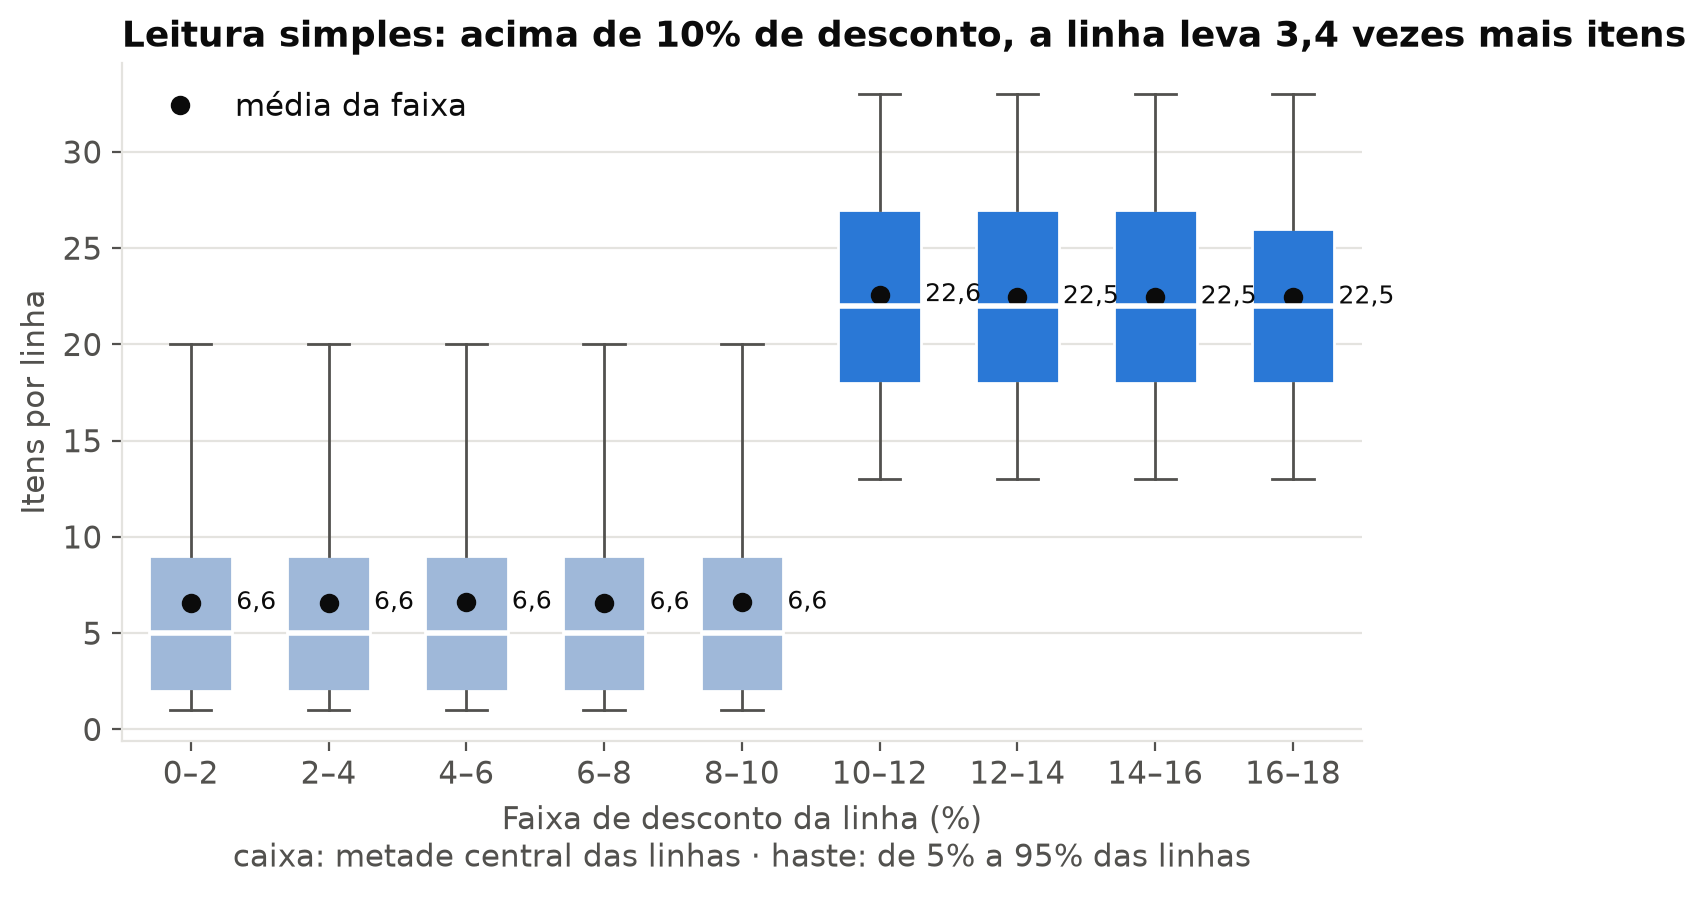

In [18]:
# [C18] Gráfico 1: a leitura simples, com a distribuição de cada faixa e não só a média
fig, ax = plt.subplots(figsize=(8, 4.4))
faixas = list(leitura_simples.index)
rotulos = [f"{int(round(max(i.left, 0) * 100))}–{int(round(i.right * 100))}" for i in faixas]
grupos = [df_fato.loc[df_fato["CLAS_FAIXA_DESCONTO"] == i, "QTD_ITENS"].to_numpy() for i in faixas]
caixas = ax.boxplot(grupos, positions=range(len(faixas)), widths=0.6, whis=(5, 95),
                    showfliers=False, patch_artist=True, medianprops={"color": "white", "linewidth": 2})
for caixa, faixa in zip(caixas["boxes"], faixas):
    caixa.set_facecolor("#9fb8d9" if faixa.right <= TETO_PROPOSTO + 1e-9 else "#2a78d6")
    caixa.set_edgecolor("white")
for parte in ("whiskers", "caps"):
    for linha in caixas[parte]:
        linha.set_color(COR_TEXTO_2)
ax.plot(range(len(faixas)), leitura_simples["mean"], "o", color=COR_TEXTO, markersize=6,
        label="média da faixa")
for x, y in enumerate(leitura_simples["mean"]):
    ax.text(x + 0.33, y, num(y, 1), va="center", color=COR_TEXTO, fontsize=9)
ax.set_xticks(range(len(faixas)))
ax.set_xticklabels(rotulos)
ax.set_title(f"Leitura simples: acima de 10% de desconto, a linha leva {num(acima_10 / ate_10, 1)} "
             "vezes mais itens", loc="left", color=COR_TEXTO)
ax.set_xlabel("Faixa de desconto da linha (%)\n"
              "caixa: metade central das linhas · haste: de 5% a 95% das linhas")
ax.set_ylabel("Itens por linha")
ax.legend(loc="upper left", frameon=False, labelcolor=COR_TEXTO)
ax.grid(axis="x", visible=False)
salvar(fig, "01-leitura-simples.png")

## 4. O efeito do desconto, separando o porte

O porte é a variável de confusão plausível (`analise-de-correlacao-entre-variaveis`, passo 7):
cliente grande compra mais e também é o único que pode receber mais de 10% de desconto. A leitura
simples mistura as duas coisas. Aqui o efeito é medido só entre clientes grandes, que é onde a
decisão acontece, e a mesma conta que mede o ganho do teto dá o ponto de equilíbrio.

In [19]:
# [C19] Funções: estimação com erro agrupado em duas dimensões e ganho do teto
COLUNAS_MODELO = ["QTD_ITENS", "QTD_LOG", "PP_DESCONTO", "COD_CLIENTE", "COD_VENDEDOR",
                  "COD_PRODUTO", "DT_MES", "CLAS_PORTE"]


def estimar(formula, dados, poisson=True):
    # Poisson por pseudo-máxima verossimilhança: o coeficiente é a variação em log da quantidade
    # média por ponto de desconto. Efeito fixo vai depois da barra e é absorvido pela biblioteca.
    funcao = pf.fepois if poisson else pf.feols
    m = funcao(formula, data=dados[COLUNAS_MODELO], vcov=AGRUPAMENTO)
    # Nenhuma linha pode ficar de fora da regressão sem aviso (o pyfixest guarda a contagem em _N).
    assert int(m._N) == len(dados), "a regressão descartou linhas"
    ic = m.confint().loc["PP_DESCONTO"]
    return {"beta": float(m.coef()["PP_DESCONTO"]), "ep": float(m.se()["PP_DESCONTO"]),
            "inf": float(ic.iloc[0]), "sup": float(ic.iloc[1]), "n": len(dados), "modelo": m}


def em_pct(b):
    return float(np.expm1(b))   # pontos de log para variação percentual


def margens_do_teto(df, teto):
    # Margem atual e margem com o teto, por linha afetada, sem perda de volume.
    afetadas = df[df["PCT_DESCONTO"] > teto]
    nova = afetadas["VLR_RECEITA_BRUTA"] * (1 - teto) - afetadas["VLR_CUSTO"]
    delta_pp = (afetadas["PCT_DESCONTO"] - teto) * 100
    return afetadas, afetadas["VLR_MARGEM"], nova, delta_pp


def ganho_do_teto(df, teto, beta):
    # Com efeito beta (truncado em zero), tirar delta_pp pontos de desconto multiplica a
    # quantidade da linha por exp(-beta * delta_pp). Sem efeito, o ganho é só o desconto retirado.
    _, atual, nova, delta_pp = margens_do_teto(df, teto)
    return float((nova * np.exp(-max(beta, 0.0) * delta_pp)).sum() - atual.sum())

In [20]:
# [C20] Ponto de equilíbrio: o efeito que zeraria o ganho do teto na janela de estimação
beta_equilibrio = brentq(lambda b: ganho_do_teto(df_grande_est, TETO_PROPOSTO, b), 1e-9, 1.0)
# Referência marginal: um ponto a mais custa 1% da receita bruta, pago pela margem extra.
equilibrio_marginal = (0.01 * df_grande_est["VLR_RECEITA_BRUTA"].sum()
                       / df_grande_est["VLR_MARGEM"].sum())
registrar("equilibrio_por_pp", em_pct(beta_equilibrio), "C20", pct(em_pct(beta_equilibrio), 1))
registrar("equilibrio_marginal_ref", equilibrio_marginal, "C20", pct(equilibrio_marginal, 1))

C20 equilibrio_por_pp: 3,2%
C20 equilibrio_marginal_ref: 2,8%


In [21]:
# [C21] Quantidade por faixa de desconto dentro de cada porte, nos 36 meses, em índice (0 a 2% = 100)
contagem = df_fato.groupby(["CLAS_PORTE", "CLAS_FAIXA_DESCONTO"], observed=True)["QTD_ITENS"].agg(
    ["mean", "size"])
dentro = contagem.loc[contagem["size"] >= MIN_LINHAS_FAIXA, "mean"].unstack(0)
indice = dentro / dentro.iloc[0] * 100
print(dentro.round(2).to_string())
print(indice.round(1).to_string())
amplitude = float((indice.max() - indice.min()).max())
registrar("dentro_amplitude_indice", amplitude, "C21", num(amplitude, 1))
for porte in ["Pequeno", "Médio", "Grande"]:
    media = df_fato.loc[df_fato["CLAS_PORTE"] == porte, "QTD_ITENS"].mean()
    registrar(f"qtd_media_{porte}", media, "C21", num(media, 1))

CLAS_PORTE           Pequeno  Médio  Grande
CLAS_FAIXA_DESCONTO                        
(-0.001, 0.02]          3.05   9.03   22.53
(0.02, 0.04]            3.05   9.05   22.54
(0.04, 0.06]            3.06   9.04   22.63
(0.06, 0.08]            3.06   9.03   22.53
(0.08, 0.1]             3.06   9.02   22.56
(0.1, 0.12]              NaN    NaN   22.59
(0.12, 0.14]             NaN    NaN   22.48
(0.14, 0.16]             NaN    NaN   22.47
(0.16, 0.18]             NaN    NaN   22.47
CLAS_PORTE           Pequeno  Médio  Grande
CLAS_FAIXA_DESCONTO                        
(-0.001, 0.02]         100.0  100.0   100.0
(0.02, 0.04]           100.2  100.2   100.1
(0.04, 0.06]           100.5  100.1   100.4
(0.06, 0.08]           100.3  100.0   100.0
(0.08, 0.1]            100.5   99.9   100.2
(0.1, 0.12]              NaN    NaN   100.3
(0.12, 0.14]             NaN    NaN    99.8
(0.14, 0.16]             NaN    NaN    99.8
(0.16, 0.18]             NaN    NaN    99.7
C21 dentro_amplitude_indice: 0,7

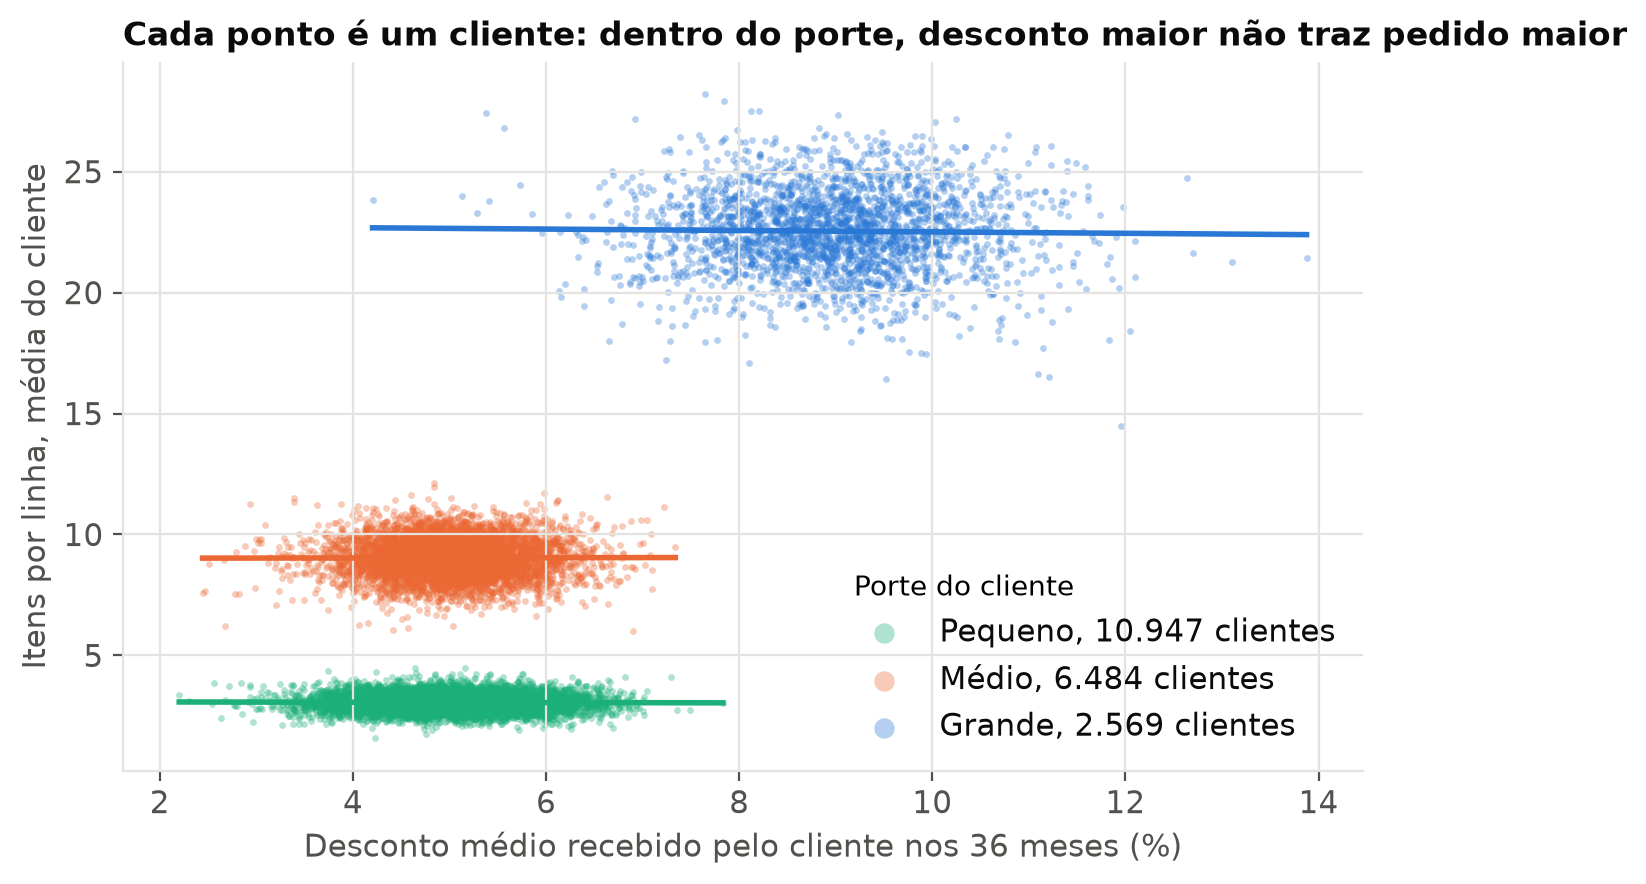

In [22]:
# [C22] Gráfico 2: cada cliente é um ponto; dentro do porte, desconto maior não traz pedido maior
df_por_cliente = df_fato.groupby(["COD_CLIENTE", "CLAS_PORTE"], observed=True).agg(
    VLR_RECEITA_BRUTA=("VLR_RECEITA_BRUTA", "sum"), VLR_DESCONTO=("VLR_DESCONTO", "sum"),
    QTD_ITENS_POR_LINHA=("QTD_ITENS", "mean")).reset_index()
df_por_cliente["PP_DESCONTO_MEDIO"] = (df_por_cliente["VLR_DESCONTO"]
                                       / df_por_cliente["VLR_RECEITA_BRUTA"] * 100)
fig, ax = plt.subplots(figsize=(8, 4.6))
for porte in ["Pequeno", "Médio", "Grande"]:
    pontos = df_por_cliente[df_por_cliente["CLAS_PORTE"] == porte]
    ax.scatter(pontos["PP_DESCONTO_MEDIO"], pontos["QTD_ITENS_POR_LINHA"], s=6, alpha=0.35,
               color=COR_PORTE[porte], linewidths=0,
               label=f"{porte}, {num(len(pontos))} clientes")
    # Reta de tendência dentro do porte, só para leitura: a estimativa formal é a da regressão.
    inclinacao = np.polyfit(pontos["PP_DESCONTO_MEDIO"], pontos["QTD_ITENS_POR_LINHA"], 1)
    xs = np.linspace(pontos["PP_DESCONTO_MEDIO"].min(), pontos["PP_DESCONTO_MEDIO"].max(), 10)
    ax.plot(xs, np.polyval(inclinacao, xs), color=COR_PORTE[porte], linewidth=2)
ax.set_title("Cada ponto é um cliente: dentro do porte, desconto maior não traz pedido maior",
             loc="left", color=COR_TEXTO, fontsize=12)
ax.set_xlabel("Desconto médio recebido pelo cliente nos 36 meses (%)")
ax.set_ylabel("Itens por linha, média do cliente")
ax.legend(loc="lower right", frameon=False, markerscale=3, labelcolor=COR_TEXTO,
          title="Porte do cliente", title_fontsize=10, alignment="left")
salvar(fig, "02-dentro-do-porte.png")

In [23]:
# [C23] Estimativa principal e robustez, na janela de estimação, entre clientes grandes
especificacoes = {
    "principal: Poisson, clientes grandes": "QTD_ITENS ~ PP_DESCONTO",
    "+ efeito fixo de produto": "QTD_ITENS ~ PP_DESCONTO | COD_PRODUTO",
    "+ efeito fixo de vendedor": "QTD_ITENS ~ PP_DESCONTO | COD_VENDEDOR",
    "+ efeito fixo de mês": "QTD_ITENS ~ PP_DESCONTO | DT_MES",
    "+ efeito fixo de cliente": "QTD_ITENS ~ PP_DESCONTO | COD_CLIENTE",
}
votantes = {nome: estimar(formula, df_grande_est) for nome, formula in especificacoes.items()}
# O logaritmo por MQO mede o efeito sobre a média do log. Com variância que cresce com a quantidade,
# esse efeito não se traduz no efeito sobre a média, que é a escala do equilíbrio, e por isso ele
# fica como leitura de robustez, fora da votação.
r_log = estimar("QTD_LOG ~ PP_DESCONTO", df_grande_est, poisson=False)
for nome, r in {**votantes, "logaritmo da quantidade (MQO, fora da decisão)": r_log}.items():
    print(f"{nome:<40} {em_pct(r['beta']):+.3%}  IC95% [{em_pct(r['inf']):+.3%}, "
          f"{em_pct(r['sup']):+.3%}]  n={r['n']}")
principal = votantes["principal: Poisson, clientes grandes"]
registrar("efeito_principal", em_pct(principal["beta"]), "C23", pct(em_pct(principal["beta"]), 3))
registrar("efeito_principal_inf", em_pct(principal["inf"]), "C23", pct(em_pct(principal["inf"]), 3))
registrar("efeito_principal_sup", em_pct(principal["sup"]), "C23", pct(em_pct(principal["sup"]), 3))
registrar("n_principal", principal["n"], "C23", num(principal["n"]))
r_cliente = votantes["+ efeito fixo de cliente"]
registrar("efeito_fe_cliente", em_pct(r_cliente["beta"]), "C23", pct(em_pct(r_cliente["beta"]), 3))
registrar("efeito_fe_cliente_inf", em_pct(r_cliente["inf"]), "C23", pct(em_pct(r_cliente["inf"]), 3))
registrar("efeito_fe_cliente_sup", em_pct(r_cliente["sup"]), "C23", pct(em_pct(r_cliente["sup"]), 3))
# Pior caso plausível do efeito: o maior limite superior entre as especificações que votam.
maior_sup = max(r["sup"] for r in votantes.values())
registrar("efeito_maior_sup_robustez", em_pct(maior_sup), "C23", pct(em_pct(maior_sup), 3))

principal: Poisson, clientes grandes     -0.031%  IC95% [-0.066%, +0.004%]  n=82955
+ efeito fixo de produto                 -0.033%  IC95% [-0.069%, +0.003%]  n=82955
+ efeito fixo de vendedor                -0.034%  IC95% [-0.063%, -0.005%]  n=82955
+ efeito fixo de mês                     -0.031%  IC95% [-0.065%, +0.004%]  n=82955
+ efeito fixo de cliente                 -0.029%  IC95% [-0.066%, +0.008%]  n=82955
logaritmo da quantidade (MQO, fora da decisão) -0.030%  IC95% [-0.067%, +0.007%]  n=82955
C23 efeito_principal: -0,031%
C23 efeito_principal_inf: -0,066%
C23 efeito_principal_sup: 0,004%
C23 n_principal: 82.955
C23 efeito_fe_cliente: -0,029%
C23 efeito_fe_cliente_inf: -0,066%
C23 efeito_fe_cliente_sup: 0,008%
C23 efeito_maior_sup_robustez: 0,008%


In [24]:
# [C24] Linha de base do estimador: a inclinação ingênua, sem separar o porte, contra a corrigida
r_sem_porte = estimar("QTD_ITENS ~ PP_DESCONTO", df_est)
r_com_porte = estimar("QTD_ITENS ~ PP_DESCONTO | CLAS_PORTE", df_est)
print(f"Sem separar o porte: {em_pct(r_sem_porte['beta']):+.2%} por ponto")
print(f"Com efeito fixo de porte: {em_pct(r_com_porte['beta']):+.3%} "
      f"[{em_pct(r_com_porte['inf']):+.3%}, {em_pct(r_com_porte['sup']):+.3%}]")
registrar("efeito_sem_porte", em_pct(r_sem_porte["beta"]), "C24", pct(em_pct(r_sem_porte["beta"]), 1))
registrar("efeito_carteira_com_porte", em_pct(r_com_porte["beta"]), "C24",
          pct(em_pct(r_com_porte["beta"]), 3))
registrar("efeito_carteira_inf", em_pct(r_com_porte["inf"]), "C24", pct(em_pct(r_com_porte["inf"]), 3))
registrar("efeito_carteira_sup", em_pct(r_com_porte["sup"]), "C24", pct(em_pct(r_com_porte["sup"]), 3))

Sem separar o porte: +7.74% por ponto
Com efeito fixo de porte: -0.021% [-0.049%, +0.006%]
C24 efeito_sem_porte: 7,7%
C24 efeito_carteira_com_porte: -0,021%
C24 efeito_carteira_inf: -0,049%
C24 efeito_carteira_sup: 0,006%


In [25]:
# [C25] Diagnóstico: a quantidade prevista acompanha a observada em cada faixa de desconto?
df_calibracao = pd.DataFrame({
    "QTD_OBSERVADA": df_grande_est["QTD_ITENS"].to_numpy(),
    "QTD_PREVISTA": principal["modelo"].predict(type="response"),
    "CLAS_FAIXA_DESCONTO": df_grande_est["CLAS_FAIXA_DESCONTO"].to_numpy()})
por_faixa = df_calibracao.groupby("CLAS_FAIXA_DESCONTO", observed=True)[
    ["QTD_OBSERVADA", "QTD_PREVISTA"]].mean()
por_faixa["desvio"] = por_faixa["QTD_OBSERVADA"] / por_faixa["QTD_PREVISTA"] - 1
print(por_faixa.round(3).to_string())
assert por_faixa["desvio"].abs().max() < TOLERANCIA_CALIBRACAO, "forma funcional não acompanha"

                     QTD_OBSERVADA  QTD_PREVISTA  desvio
CLAS_FAIXA_DESCONTO                                     
(-0.001, 0.02]              22.534        22.607  -0.003
(0.02, 0.04]                22.597        22.592   0.000
(0.04, 0.06]                22.619        22.579   0.002
(0.06, 0.08]                22.548        22.565  -0.001
(0.08, 0.1]                 22.591        22.551   0.002
(0.1, 0.12]                 22.644        22.537   0.005
(0.12, 0.14]                22.462        22.523  -0.003
(0.14, 0.16]                22.512        22.509   0.000
(0.16, 0.18]                22.453        22.496  -0.002


In [26]:
# [C26] Confirmação nos 12 meses seguintes, com a mesma especificação principal
r_conf = estimar("QTD_ITENS ~ PP_DESCONTO", df_grande_conf)
beta_equilibrio_conf = brentq(lambda b: ganho_do_teto(df_grande_conf, TETO_PROPOSTO, b), 1e-9, 1.0)
registrar("efeito_conf", em_pct(r_conf["beta"]), "C26", pct(em_pct(r_conf["beta"]), 3))
registrar("efeito_conf_inf", em_pct(r_conf["inf"]), "C26", pct(em_pct(r_conf["inf"]), 3))
registrar("efeito_conf_sup", em_pct(r_conf["sup"]), "C26", pct(em_pct(r_conf["sup"]), 3))
registrar("equilibrio_conf", em_pct(beta_equilibrio_conf), "C26", pct(em_pct(beta_equilibrio_conf), 1))

C26 efeito_conf: -0,022%
C26 efeito_conf_inf: -0,070%
C26 efeito_conf_sup: 0,027%
C26 equilibrio_conf: 3,2%


In [27]:
# [C27] Decisão pelo critério do enquadramento, com a regra de concordância do adendo
def decidir(r, equilibrio):
    if r["sup"] < equilibrio:
        return "recomendar o teto"
    if r["inf"] > equilibrio:
        return "manter a política"
    return "inconclusivo"


# Votam só as especificações Poisson do cliente grande, cada janela contra o próprio equilíbrio.
# A carteira inteira mede outro efeito e o logaritmo está em outra escala: os dois ficam de fora.
votos = {nome: decidir(r, beta_equilibrio) for nome, r in votantes.items()}
votos["confirmação: 12 meses seguintes"] = decidir(r_conf, beta_equilibrio_conf)
decisao_principal = votos["principal: Poisson, clientes grandes"]
decisao = decisao_principal if all(v == decisao_principal for v in votos.values()) else "inconclusivo"
for nome, voto in votos.items():
    print(f"{nome:<40} {voto}")
print("Decisão:", decisao)
registrar("decisao", decisao, "C27", decisao)

principal: Poisson, clientes grandes     recomendar o teto
+ efeito fixo de produto                 recomendar o teto
+ efeito fixo de vendedor                recomendar o teto
+ efeito fixo de mês                     recomendar o teto
+ efeito fixo de cliente                 recomendar o teto
confirmação: 12 meses seguintes          recomendar o teto
Decisão: recomendar o teto
C27 decisao: recomendar o teto


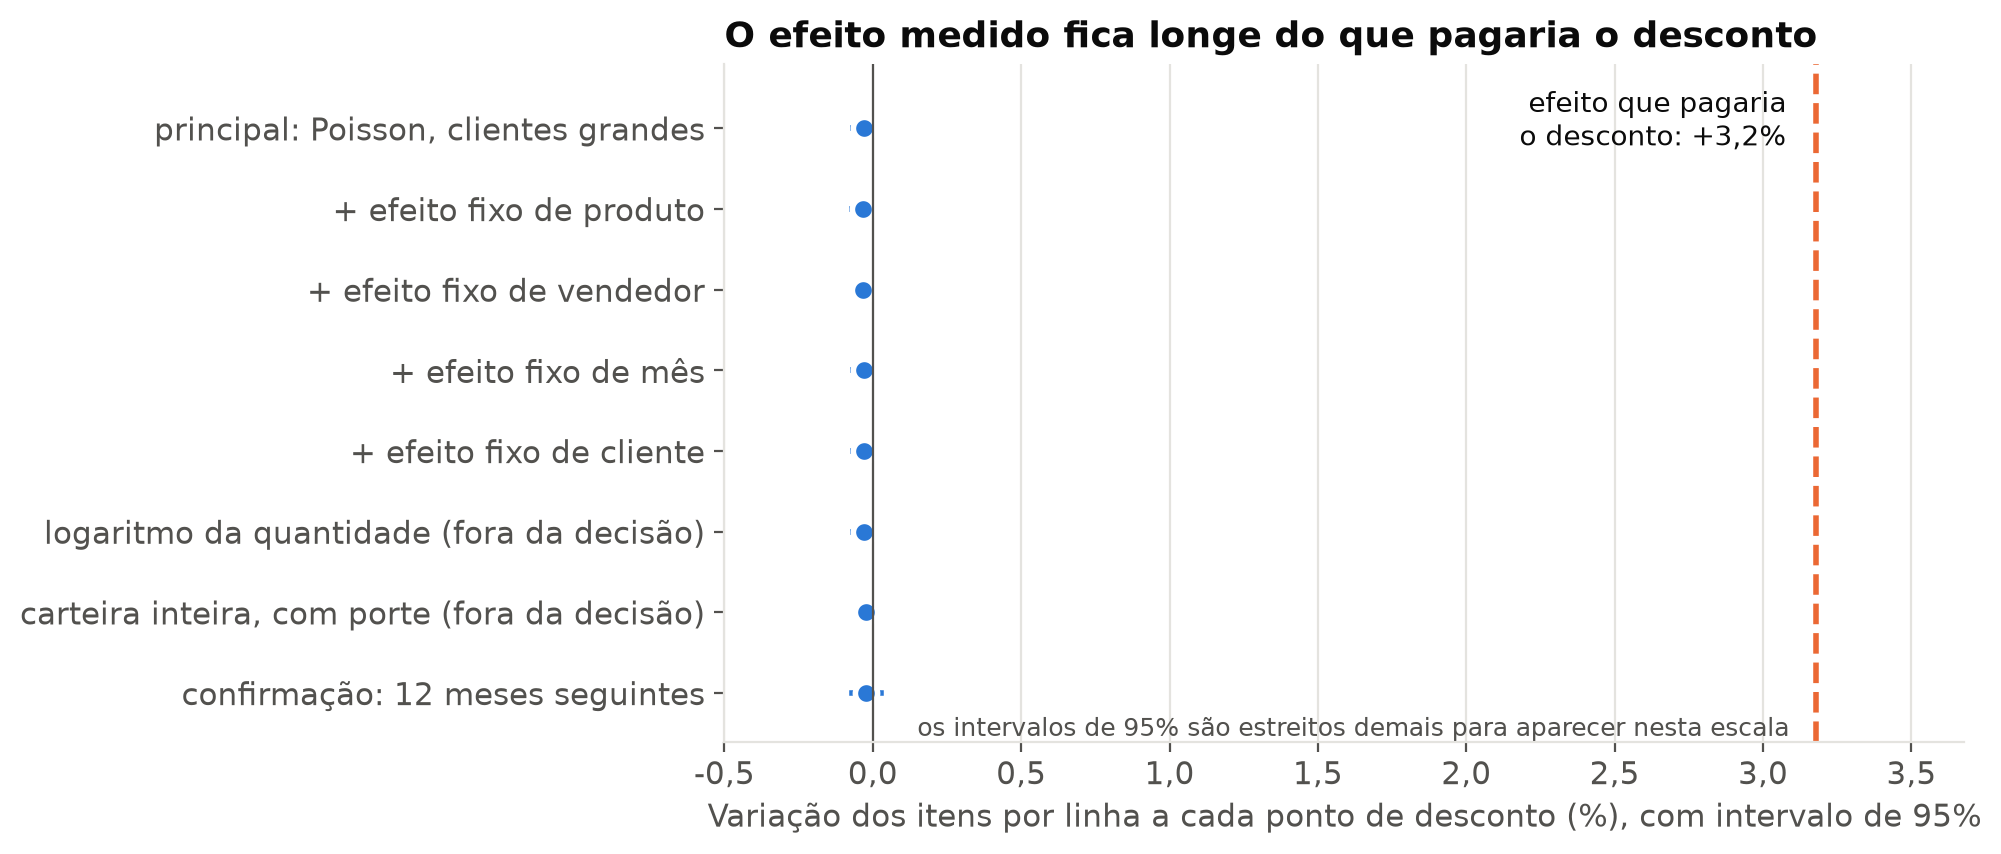

In [28]:
# [C28] Gráfico 3: o efeito estimado contra o efeito que pagaria o desconto
no_grafico = {**votantes, "logaritmo da quantidade (fora da decisão)": r_log,
              "carteira inteira, com porte (fora da decisão)": r_com_porte,
              "confirmação: 12 meses seguintes": r_conf}
ordem = list(no_grafico)
fig, ax = plt.subplots(figsize=(8, 4.4))
for i, nome in enumerate(ordem):
    r, y = no_grafico[nome], len(ordem) - 1 - i
    ax.plot([em_pct(r["inf"]) * 100, em_pct(r["sup"]) * 100], [y, y], color="#2a78d6", linewidth=2)
    ax.plot(em_pct(r["beta"]) * 100, y, "o", color="#2a78d6", markersize=8,
            markeredgecolor="white", markeredgewidth=2)
eq = em_pct(beta_equilibrio) * 100
ax.axvline(0, color=COR_TEXTO_2, linewidth=0.8)
ax.axvline(eq, color="#eb6834", linewidth=2, linestyle="--")
ax.text(eq - 0.1, len(ordem) - 0.5, f"efeito que pagaria\no desconto: +{num(eq, 1)}%",
        color=COR_TEXTO, ha="right", va="top", fontsize=10)
ax.set_yticks(range(len(ordem)))
ax.set_yticklabels(list(reversed(ordem)))
ax.set_xlim(-0.5, eq + 0.5)
ax.set_ylim(-0.6, len(ordem) - 0.2)
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: num(v, 1)))
ax.text(0.15, -0.45, "os intervalos de 95% são estreitos demais para aparecer nesta escala",
        color=COR_TEXTO_2, fontsize=9, va="center")
ax.set_xlabel("Variação dos itens por linha a cada ponto de desconto (%), com intervalo de 95%")
ax.set_title("O efeito medido fica longe do que pagaria o desconto", loc="left", color=COR_TEXTO)
ax.grid(axis="y", visible=False)
salvar(fig, "03-efeito-contra-equilibrio.png")

## 5. Leitura exploratória: o desconto traz o cliente de volta?

Sem voto na decisão. O efeito por linha não responde se o desconto fideliza, e aqui a pergunta é
outra: entre os clientes grandes, quem recebeu desconto médio maior nos primeiros 24 meses fez mais
pedidos nos 12 meses seguintes? O desconto vem antes do pedido que ele explicaria, e os pedidos
dos 24 meses entram como controle da frequência de cada cliente.

In [29]:
# [C29] Recompra: desconto médio ponderado na estimação contra pedidos na confirmação
def por_cliente(df):
    return df.groupby("COD_CLIENTE").agg(
        VLR_RECEITA_BRUTA=("VLR_RECEITA_BRUTA", "sum"), VLR_DESCONTO=("VLR_DESCONTO", "sum"),
        QTD_PEDIDOS=("COD_PEDIDO", "nunique"))


df_recompra = (por_cliente(df_grande_est)
               .join(por_cliente(df_grande_conf)[["QTD_PEDIDOS"]], rsuffix="_SEGUINTES", how="left")
               .fillna({"QTD_PEDIDOS_SEGUINTES": 0}).reset_index())
df_recompra["PP_DESCONTO_MEDIO"] = (df_recompra["VLR_DESCONTO"] / df_recompra["VLR_RECEITA_BRUTA"]
                                    * 100)
m_recompra = pf.fepois("QTD_PEDIDOS_SEGUINTES ~ PP_DESCONTO_MEDIO + QTD_PEDIDOS", data=df_recompra,
                       vcov="hetero")
ic = m_recompra.confint().loc["PP_DESCONTO_MEDIO"]
b = float(m_recompra.coef()["PP_DESCONTO_MEDIO"])
registrar("recompra_clientes", len(df_recompra), "C29", num(len(df_recompra)))
registrar("recompra_media_pedidos", df_recompra["QTD_PEDIDOS_SEGUINTES"].mean(), "C29",
          num(df_recompra["QTD_PEDIDOS_SEGUINTES"].mean(), 1))
registrar("recompra_efeito", em_pct(b), "C29", pct(em_pct(b), 1))
registrar("recompra_inf", em_pct(ic.iloc[0]), "C29", pct(em_pct(ic.iloc[0]), 1))
registrar("recompra_sup", em_pct(ic.iloc[1]), "C29", pct(em_pct(ic.iloc[1]), 1))

C29 recompra_clientes: 2.567


C29 recompra_media_pedidos: 4,4
C29 recompra_efeito: 0,2%
C29 recompra_inf: -1,2%
C29 recompra_sup: 1,6%


## 6. O teto de 10% nos últimos 12 meses, e o que o anularia

O ganho é calculado sobre as linhas de clientes grandes com desconto acima do teto, nos 12 meses de
confirmação. É uma conta sobre todos os clientes do período, e não uma amostra, então não há
incerteza amostral a declarar sobre ela (`populacoes-amostras-e-amostragem`). A incerteza que
importa está no comportamento que a base não registra, e por isso a análise mostra quanto volume,
ou quantos clientes, precisariam sumir para o ganho desaparecer
(`calculo-de-roi-de-projeto-de-dados`, passo 6), em vez de uma faixa em torno do ponto.

In [30]:
# [C30] Ganho do teto de 10% para o cliente grande, e a perda que o zeraria
afetadas, atual, nova, delta_pp = margens_do_teto(df_grande_conf, TETO_PROPOSTO)
ganho_ponto = float(nova.sum() - atual.sum())
margem_grande_12m = df_grande_conf["VLR_MARGEM"].sum()
# Perda de volume, só nas linhas afetadas, que zeraria o ganho.
perda_equilibrio = 1 - atual.sum() / nova.sum()
# Perda uniforme de volume em todas as linhas do cliente grande, ou saída de clientes que somem
# essa fração da margem, que zeraria o ganho: G - L (M + G) = 0.
saida_equilibrio = ganho_ponto / (ganho_ponto + margem_grande_12m)
registrar("teto_ganho_ponto", ganho_ponto, "C30", brl_mi(ganho_ponto))
registrar("teto_linhas_afetadas_share", len(afetadas) / len(df_grande_conf), "C30",
          pct(len(afetadas) / len(df_grande_conf), 0))
registrar("teto_ganho_sobre_margem_grande", ganho_ponto / margem_grande_12m, "C30",
          pct(ganho_ponto / margem_grande_12m, 1))
registrar("teto_ganho_sobre_margem_total", ganho_ponto / base_12m["margem"].sum(), "C30",
          pct(ganho_ponto / base_12m["margem"].sum(), 1))
registrar("teto_perda_equilibrio", perda_equilibrio, "C30", pct(perda_equilibrio, 0))
registrar("teto_saida_equilibrio", saida_equilibrio, "C30", pct(saida_equilibrio, 1))

C30 teto_ganho_ponto: R$ 5,5 milhões
C30 teto_linhas_afetadas_share: 44%
C30 teto_ganho_sobre_margem_grande: 5,0%
C30 teto_ganho_sobre_margem_total: 1,8%
C30 teto_perda_equilibrio: 12%
C30 teto_saida_equilibrio: 4,8%


In [31]:
# [C31] Ganho por cliente e sensibilidade do ganho à saída de clientes
df_ganho_cliente = pd.DataFrame({
    "COD_CLIENTE": afetadas["COD_CLIENTE"], "VLR_MARGEM_ATUAL": atual,
    "VLR_MARGEM_NOVA": nova}).groupby("COD_CLIENTE").sum()
clientes_ativos = pd.Index(df_grande_conf["COD_CLIENTE"].unique())
# Cliente ativo sem linha acima do teto entra com ganho zero.
df_ganho_cliente = df_ganho_cliente.reindex(clientes_ativos, fill_value=0.0)
ganho_cli = (df_ganho_cliente["VLR_MARGEM_NOVA"] - df_ganho_cliente["VLR_MARGEM_ATUAL"]).to_numpy()
# Com o pior efeito plausível do desconto, o ganho quase não muda: o limite superior é quase zero.
ganho_pior = ganho_do_teto(df_grande_conf, TETO_PROPOSTO, maior_sup)
registrar("teto_ganho_pior", ganho_pior, "C31", brl_mi(ganho_pior))
# Ganho líquido se clientes grandes com margem média, somando x da margem do porte, saírem:
# G (1 - x) - x M, que zera em x = G / (G + M).
for saida in SAIDAS_CENARIO:
    liquido = ganho_ponto * (1 - saida) - saida * margem_grande_12m
    registrar(f"saida_{int(round(saida * 100))}_pct", saida, "C31", pct(saida, 0))
    registrar(f"saida_{int(round(saida * 100))}_liquido", liquido, "C31", brl_mi(liquido))

C31 teto_ganho_pior: R$ 5,5 milhões
C31 saida_1_pct: 1%
C31 saida_1_liquido: R$ 4,4 milhões
C31 saida_2_pct: 2%
C31 saida_2_liquido: R$ 3,2 milhões
C31 saida_3_pct: 3%
C31 saida_3_liquido: R$ 2,0 milhões


In [32]:
# [C32] Exposição por conta: quantos clientes grandes concentram o ganho do teto
ganho_ordenado = np.sort(ganho_cli[ganho_cli > 0])[::-1]
acumulado = np.cumsum(ganho_ordenado) / ganho_ordenado.sum()
clientes_metade = int(np.searchsorted(acumulado, 0.5) + 1)
afetados = int((ganho_cli > 0).sum())
registrar("exposicao_clientes_grandes", len(clientes_ativos), "C32", num(len(clientes_ativos)))
registrar("exposicao_clientes_afetados", afetados, "C32", num(afetados))
registrar("exposicao_share_afetados", afetados / len(clientes_ativos), "C32",
          pct(afetados / len(clientes_ativos), 0))
registrar("exposicao_clientes_metade", clientes_metade, "C32", num(clientes_metade))
registrar("exposicao_share_metade", clientes_metade / afetados, "C32", pct(clientes_metade / afetados, 0))
media_por_conta = float(ganho_ordenado.mean())
registrar("exposicao_ganho_medio_conta", media_por_conta, "C32", f"R$ {num(media_por_conta / 1e3, 1)} mil")
maior_conta = float(ganho_ordenado[0])
registrar("exposicao_maior_conta", maior_conta, "C32", f"R$ {num(maior_conta / 1e3, 1)} mil")

C32 exposicao_clientes_grandes: 2.531
C32 exposicao_clientes_afetados: 2.470
C32 exposicao_share_afetados: 98%
C32 exposicao_clientes_metade: 600
C32 exposicao_share_metade: 24%
C32 exposicao_ganho_medio_conta: R$ 2,2 mil
C32 exposicao_maior_conta: R$ 10,7 mil


In [33]:
# [C33] Três tetos para o cliente grande, na mesma conta (exploratório, fora do critério)
linhas_sens = []
for t in TETOS_SENSIBILIDADE:
    af, at, nv, _ = margens_do_teto(df_grande_conf, t)
    linhas_sens.append({"teto": t, "linhas_afetadas": len(af) / len(df_grande_conf),
                        "ganho_sem_perda": ganho_do_teto(df_grande_conf, t, 0.0),
                        "ganho_pior": ganho_do_teto(df_grande_conf, t, maior_sup),
                        "perda_equilibrio": 1 - at.sum() / nv.sum()})
sensibilidade = pd.DataFrame(linhas_sens)
print(sensibilidade.assign(ganho_sem_perda=lambda d: d["ganho_sem_perda"] / 1e6,
                           ganho_pior=lambda d: d["ganho_pior"] / 1e6).round(3).to_string())
for _, linha in sensibilidade.iterrows():
    sufixo = f"{int(round(linha['teto'] * 100))}"
    registrar(f"sens_{sufixo}_ganho", linha["ganho_sem_perda"], "C33", brl_mi(linha["ganho_sem_perda"]))
    registrar(f"sens_{sufixo}_linhas", linha["linhas_afetadas"], "C33", pct(linha["linhas_afetadas"], 0))
    registrar(f"sens_{sufixo}_perda_eq", linha["perda_equilibrio"], "C33", pct(linha["perda_equilibrio"], 0))

   teto  linhas_afetadas  ganho_sem_perda  ganho_pior  perda_equilibrio
0  0.10            0.443            5.521       5.506             0.116
1  0.12            0.331            3.105       3.098             0.092
2  0.14            0.220            1.378       1.375             0.066
C33 sens_10_ganho: R$ 5,5 milhões
C33 sens_10_linhas: 44%
C33 sens_10_perda_eq: 12%
C33 sens_12_ganho: R$ 3,1 milhões
C33 sens_12_linhas: 33%
C33 sens_12_perda_eq: 9%
C33 sens_14_ganho: R$ 1,4 milhão
C33 sens_14_linhas: 22%
C33 sens_14_perda_eq: 7%


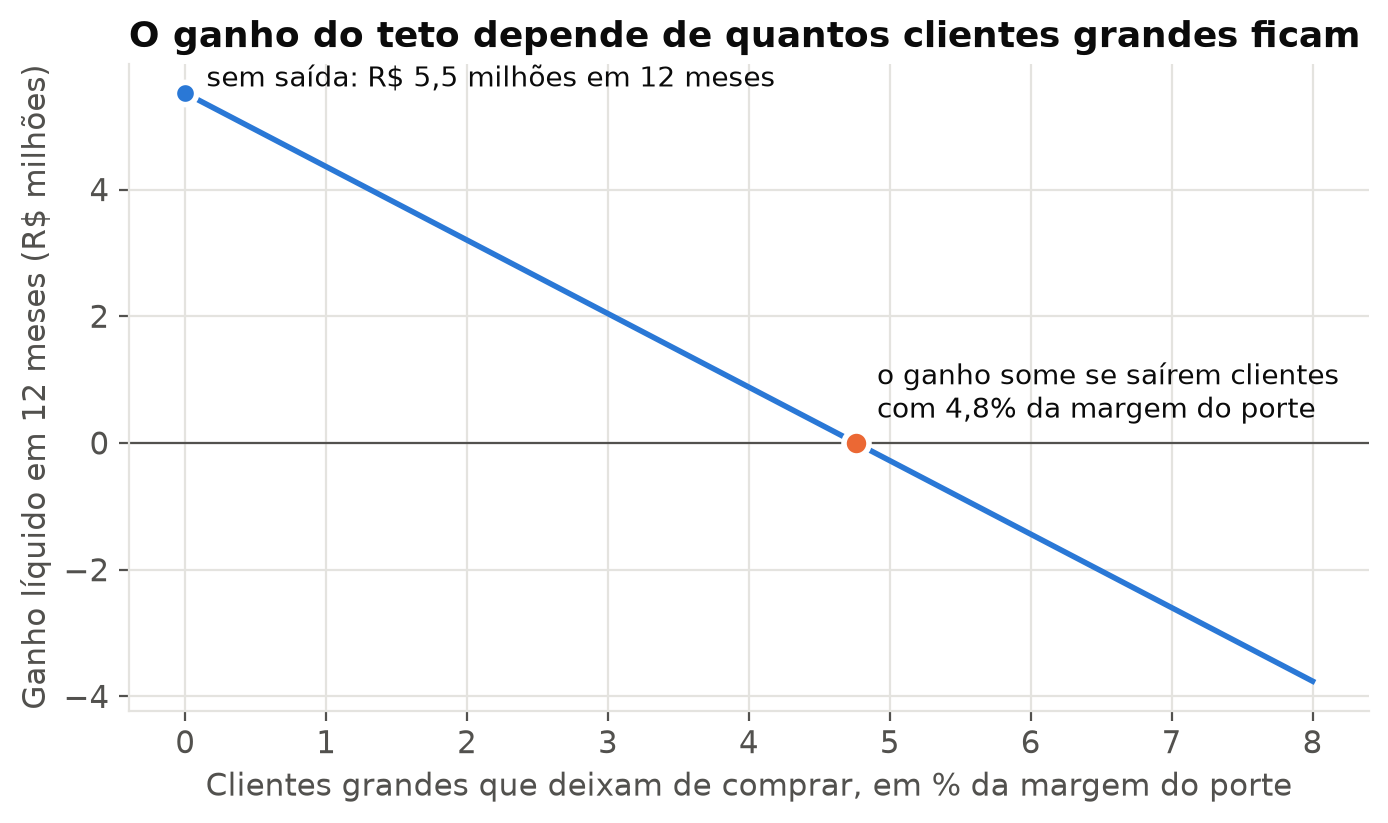

In [34]:
# [C34] Gráfico 4: o ganho do teto conforme a saída de clientes grandes
saidas = np.linspace(0, 0.08, 81)
liquidos = (ganho_ponto * (1 - saidas) - saidas * margem_grande_12m) / 1e6
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(saidas * 100, liquidos, color="#2a78d6", linewidth=2)
ax.axhline(0, color=COR_TEXTO_2, linewidth=0.8)
ax.plot(0, liquidos[0], "o", color="#2a78d6", markersize=8, markeredgecolor="white", markeredgewidth=2)
ax.text(0.15, liquidos[0], f"sem saída: {brl_mi(ganho_ponto)} em 12 meses", color=COR_TEXTO,
        fontsize=10, va="bottom")
ax.plot(saida_equilibrio * 100, 0, "o", color="#eb6834", markersize=9, markeredgecolor="white",
        markeredgewidth=2)
ax.text(saida_equilibrio * 100 + 0.15, 0.25,
        f"o ganho some se saírem clientes\ncom {pct(saida_equilibrio, 1)} da margem do porte",
        color=COR_TEXTO, fontsize=10, va="bottom")
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: num(v, 0)))
ax.set_xlabel("Clientes grandes que deixam de comprar, em % da margem do porte")
ax.set_ylabel("Ganho líquido em 12 meses (R$ milhões)")
ax.set_title("O ganho do teto depende de quantos clientes grandes ficam", loc="left", color=COR_TEXTO)
salvar(fig, "04-ganho-do-teto.png")

## 7. O piloto que mede o que a base não registra

A base não guarda o pedido que deixou de acontecer, então o risco de o cliente grande comprar menos
com o teto só se mede aplicando o teto. O desenho segue `planejamento-e-analise-de-teste-ab` e
`dimensionamento-e-desenho-de-amostra`: metade dos clientes grandes do cadastro recebe o teto por 12
meses, e a outra metade fica na política atual. O sorteio é feito dentro de cada vendedor
principal, para os dois grupos terem a mesma mistura de vendedores, e o resultado só é lido ao fim
dos 12 meses, sem espiar no meio. Na base, o vendedor principal não explica mais da variação da
métrica do que o acaso explicaria, então o sorteio por vendedor serve ao equilíbrio dos grupos e não
muda o tamanho necessário.

O teste é de não inferioridade, unilateral a 5%. A métrica principal é a parcela de clientes
grandes sem compra no segundo semestre do piloto, e a margem de não inferioridade é a alta que a
saída de equilíbrio provocaria nela, `equilíbrio × (1 − parcela sem compra)`, supondo que quem sai
tem a margem média do porte. Quem deixar de comprar nos primeiros seis meses aparece inteiro na
métrica; a saída que só começa no segundo semestre aparece diluída, e esse é o limite do desenho. A
leitura do poder é a de não inferioridade: a chance de o piloto demonstrar que a alta fica abaixo
da margem quando não há saída real, e a maior alta real que ainda deixa 80% de chance. A métrica
secundária é o volume por cliente no ano do piloto.

In [35]:
# [C35] Desenho do piloto de 12 meses: sorteio por vendedor e leitura de não inferioridade
clientes_cadastro = pd.Index(
    df_dim_cliente.loc[df_dim_cliente["CLAS_PORTE"] == "Grande", "COD_CLIENTE"])
df_grande = df_fato[df_fato["CLAS_PORTE"] == "Grande"]
# Vendedor principal: o que mais atendeu pedidos do cliente nos 36 meses. É o estrato do sorteio.
vendedor_principal = (df_grande.groupby(["COD_CLIENTE", "COD_VENDEDOR"])["COD_PEDIDO"].nunique()
                      .reset_index().sort_values(["COD_CLIENTE", "COD_PEDIDO"], ascending=[True, False])
                      .drop_duplicates("COD_CLIENTE").set_index("COD_CLIENTE")["COD_VENDEDOR"]
                      .reindex(clientes_cadastro))
assert vendedor_principal.notna().all(), "cliente grande sem vendedor principal: não entra no sorteio"
vendedores_por_cliente = df_grande.groupby("COD_CLIENTE")["COD_VENDEDOR"].nunique().mean()

# Sorteio estratificado com semente: metade de cada vendedor principal vai para o teto.
rng = np.random.default_rng(SEMENTE)
grupo = pd.Series("controle", index=clientes_cadastro)
for _, clientes in vendedor_principal.groupby(vendedor_principal):
    sorteados = rng.permutation(clientes.index.to_numpy())
    grupo[sorteados[: int(round(len(sorteados) * FRACAO_PILOTO))]] = "teto"
n_por_grupo = int(grupo.value_counts().min())


def volume_por_cliente(meses):
    # Volume de cada cliente grande do cadastro nos últimos `meses` da base, com zero para quem
    # não comprou, que é o que o piloto vai observar.
    inicio = pd.Timestamp(FIM_CONFIRMACAO) - pd.DateOffset(months=meses)
    janela = df_grande[df_grande["DT_VENDA"] > inicio]
    return janela.groupby("COD_CLIENTE")["QTD_ITENS"].sum().reindex(clientes_cadastro, fill_value=0)


def parcela_entre_vendedores(serie):
    # Fração da variância da métrica explicada pelo vendedor principal; o sorteio dentro de cada
    # vendedor tira essa parte da comparação entre os grupos.
    return float(serie.groupby(vendedor_principal).transform("mean").var() / serie.var())


sem_compra_cliente = (volume_por_cliente(MESES_LEITURA_SAIDA) == 0).astype(float)
sem_compra = float(sem_compra_cliente.mean())
erro_padrao = np.sqrt(2 * sem_compra * (1 - sem_compra) / n_por_grupo)
margem_ni = saida_equilibrio * (1 - sem_compra)
poder_sem_saida = float(norm.cdf(margem_ni / erro_padrao - Z_UNILATERAL_95))
alta_real_80 = margem_ni - (Z_UNILATERAL_95 + Z_PODER_80) * erro_padrao
volume_ano = volume_por_cliente(MESES_PILOTO)
queda_detectavel = ((Z_UNILATERAL_95 + Z_PODER_80) * volume_ano.std(ddof=1)
                    * np.sqrt(2 / n_por_grupo) / volume_ano.mean())
print(grupo.value_counts().to_string())
print(f"Margem de não inferioridade {margem_ni:.2%}; poder sem saída real {poder_sem_saida:.0%}; "
      f"alta real com 80% de poder {alta_real_80:.2%}; queda de volume detectável {queda_detectavel:.1%}")
registrar("piloto_clientes_por_grupo", n_por_grupo, "C35", num(n_por_grupo))
registrar("piloto_vendedores_por_cliente", vendedores_por_cliente, "C35", num(vendedores_por_cliente, 0))
# Só pelo acaso, k grupos explicam cerca de (k - 1) / (n - 1) da variância de n observações.
parcela_vendedor = parcela_entre_vendedores(sem_compra_cliente)
parcela_acaso = (vendedor_principal.nunique() - 1) / (len(clientes_cadastro) - 1)
registrar("piloto_parcela_vendedor", parcela_vendedor, "C35", pct(parcela_vendedor, 0))
registrar("piloto_parcela_acaso", parcela_acaso, "C35", pct(parcela_acaso, 0))
registrar("piloto_sem_compra_semestre", sem_compra, "C35", pct(sem_compra, 0))
registrar("piloto_saida_no_equilibrio", margem_ni, "C35", num(margem_ni * 100, 1))
registrar("piloto_poder_sem_saida", poder_sem_saida, "C35", pct(poder_sem_saida, 0))
registrar("piloto_alta_real_80", alta_real_80, "C35", num(alta_real_80 * 100, 1))
registrar("piloto_poder_alvo", norm.cdf(Z_PODER_80), "C35", pct(norm.cdf(Z_PODER_80), 0))
registrar("piloto_queda_volume_ano", queda_detectavel, "C35", pct(queda_detectavel, 0))

controle    1285
teto        1284
Margem de não inferioridade 4.19%; poder sem saída real 95%; alta real com 80% de poder 1.00%; queda de volume detectável 6.1%
C35 piloto_clientes_por_grupo: 1.284
C35 piloto_vendedores_por_cliente: 10
C35 piloto_parcela_vendedor: 5%
C35 piloto_parcela_acaso: 6%
C35 piloto_sem_compra_semestre: 12%
C35 piloto_saida_no_equilibrio: 4,2
C35 piloto_poder_sem_saida: 95%
C35 piloto_alta_real_80: 1,0
C35 piloto_poder_alvo: 80%
C35 piloto_queda_volume_ano: 6%


In [36]:
# [C36] Grava os números do relatório, cada um com a célula que o gerou
def serializavel(v):
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating, np.bool_)):
        return float(v) if isinstance(v, np.floating) else bool(v)
    return v


ARQUIVO_RESULTADOS.write_text(json.dumps(
    {k: {**d, "valor": serializavel(d["valor"])} for k, d in RESULTADOS.items()},
    ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print(len(RESULTADOS), "números gravados em", ARQUIVO_RESULTADOS)

84 números gravados em evidencias\resultados.json


## 8. Leitura do resultado

A conclusão e as limitações estão escritas no [relatório](relatorio.md), com cada número
apontando para a célula que o gerou. Em resumo: a leitura simples sugere que o desconto multiplica
o volume, mas a diferença inteira vem do porte do cliente. Dentro do mesmo porte o desconto não
move a quantidade, nem na janela de estimação nem nos 12 meses seguintes, e o efeito medido fica
longe do mínimo que pagaria o desconto. Pelo critério escrito antes, a decisão é a que a célula
`[C27]` imprime, e o piloto da célula `[C35]` é o passo que mede o risco que a base não
registra.

O que a base sintética não permite afirmar está no relatório, e a principal limitação vem da
própria natureza da base: ela não registra o pedido que deixou de acontecer.